<a href="https://colab.research.google.com/github/AngelikaBaloy/DS4002-Project2-Group5/blob/main/02_Airline_Project_Analysis_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS4002 - Group 5 - Airline Project Analysis

### Group Members: Angelika Baloy, Samuel Bromberg, Inmar Chavarria

## IAD Flight Departure Delay Rates: ARIMA & SARIMA



In [1]:
# Packages required for analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

In [2]:
# Combined datasets (created from EDA/Cleaning script)
data_24 = pd.read_csv("IAD_2024_Combined.csv")
data_25 = pd.read_csv("IAD_2025_Combined.csv")


In [3]:
# Cleaning applied to both years

# This removes cancelled flights. Cancelled flights have a departure time of 0:00 and a delay of 0 minutes.

def clean_flights(data):
    data = data.copy()
    data["Date (MM/DD/YYYY)"] = pd.to_datetime(data["Date (MM/DD/YYYY)"])
    data["Departure delay (Minutes)"] = pd.to_numeric(data["Departure delay (Minutes)"], errors="coerce")
    cancelled = data["Actual departure time"].astype(str).isin(["0:00", "00:00"])
    print("Cancelled flights removed:", cancelled.sum())
    data = data[~cancelled]
    # 1 if the flight left 15+ minutes late (FAA definition of a delay)
    data["Delayed"] = (data["Departure delay (Minutes)"] >= 15).astype(int)
    return data

data_24 = clean_flights(data_24) # Removes 488 cancelled flights
data_25 = clean_flights(data_25) # Removes 222 cancelled flights

Cancelled flights removed: 488
Cancelled flights removed: 222


In [4]:
# Daily series: average departure delay and % of flights delayed

# We'll be looking at daily average departure delay in minutes and the proportion of flights experiencing 15+ minute delays.
# We'll create prediction models for both and compare the accuracies.

def daily_series(data):
    daily = data.groupby("Date (MM/DD/YYYY)").agg(
        avg_delay=("Departure delay (Minutes)", "mean"),
        delay_rate=("Delayed", "mean")
    )
    daily["delay_rate"] = daily["delay_rate"] * 100
    daily.index.name = "Date"
    # Give the index a daily frequency so statsmodels knows the spacing between rows
    daily = daily.sort_index().asfreq("D")
    # Fill any day with no flights from its neighbors
    return daily.interpolate()

daily_24 = daily_series(data_24)
daily_25 = daily_series(data_25)

daily_avg_24 = daily_24["avg_delay"].rename("Average Departure Delay")
daily_rate_24 = daily_24["delay_rate"].rename("Departure Delay Rate")
daily_avg_25 = daily_25["avg_delay"].rename("Average Departure Delay")
daily_rate_25 = daily_25["delay_rate"].rename("Departure Delay Rate")

print(daily_24.head())

            avg_delay  delay_rate
Date                             
2024-01-01   8.977528   14.606742
2024-01-02   0.406593    6.593407
2024-01-03   8.900000    8.888889
2024-01-04   3.377778   15.555556
2024-01-05   4.211111   10.000000


In [5]:
# Dates to forecast: every day in 2025
dates_2025 = pd.date_range(start="2025-01-01", end="2025-12-31", freq="D")

In [7]:
# checking for stationarity in both series

for name, series in [("Average departure delay", daily_avg_24), ("Departure delay rate", daily_rate_24)]:
    result = adfuller(series)
    print(name)
    print('  ADF Statistic: %f' % result[0])
    print('  p-value: %f' % result[1])
# if p > .05, the data are non-stationary

# Both p-values are above .05, so the data are non-stationary.
# This means differencing is required, since ARIMA models assume stationarity.

Average departure delay
  ADF Statistic: -2.835039
  p-value: 0.053440
Departure delay rate
  ADF Statistic: -2.777743
  p-value: 0.061524


/tmp/ipykernel_6448/55953405.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series)
/tmp/ipykernel_6448/55953405.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series)


In [8]:
# Yearly seasonality: Fourier terms

# Because delays can vary in length throughout the year, a wave may be more appropriate.
def fourier_terms(dates, K=3, period=365.25):
    """Sine/cosine waves of the day of the year.
    K = number of wave pairs: higher K = a more detailed yearly curve."""
    day = dates.dayofyear.values
    terms = {}
    for k in range(1, K + 1):
        terms[f"sin{k}"] = np.sin(2 * np.pi * k * day / period)
        terms[f"cos{k}"] = np.cos(2 * np.pi * k * day / period)
    return pd.DataFrame(terms, index=dates)

exog_24 = fourier_terms(daily_24.index)
exog_25 = fourier_terms(dates_2025)

In [9]:
# ADF test after removing yearly seasonality
from statsmodels.regression.linear_model import OLS
import statsmodels.api as sm

adf_deseason_rows = []
for name, series in [("Average departure delay", daily_avg_24), ("Departure delay rate", daily_rate_24)]:
    seasonal_fit = OLS(series.values, sm.add_constant(exog_24.values)).fit()
    deseasonalized = series.values - seasonal_fit.fittedvalues
    result = adfuller(deseasonalized)
    print(name, "(yearly seasonality removed)")
    print('  ADF Statistic: %f' % result[0])
    print('  p-value: %f' % result[1])
    adf_deseason_rows.append({"Series": name, "ADF Statistic": result[0], "p-value": result[1]})

pd.DataFrame(adf_deseason_rows).to_csv("adf_deseasonalized_tests.csv", index=False)

# This cell addresses the non-significant p-values we calculated in the previous cell.
# ARIMA and SARIMA will run on this differenced data and predict a trend.

Average departure delay (yearly seasonality removed)
  ADF Statistic: -5.867932
  p-value: 0.000000
Departure delay rate (yearly seasonality removed)
  ADF Statistic: -13.056633
  p-value: 0.000000


/tmp/ipykernel_6448/3887122047.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(deseasonalized)
/tmp/ipykernel_6448/3887122047.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(deseasonalized)


In [10]:
# Model fitting and forecasting

def fit_and_forecast(series, lower=None, upper=None):
    """Fits a baseline ARIMA and a SARIMA model to a 2024 series and forecasts 2025."""

    # Log transform to shrink the influence of extreme days.
    # The shift keeps every value above 0 (some days have negative average delays).
    shift = 1 - series.min()
    series_log = np.log(series + shift)

    # Baseline: plain ARIMA
    arima_fit = ARIMA(series, order=(1, 0, 1)).fit()
    arima_pred = arima_fit.forecast(steps=len(dates_2025))

    # SARIMA: weekly seasonal component (period 7) + yearly Fourier terms
    # We predict the SARIMA will perform better and make more accurate predictions
    sarima_fit = SARIMAX(
        series_log,
        exog=exog_24,
        order=(1, 0, 1),
        seasonal_order=(1, 0, 1, 7),
        trend="c"
    ).fit(disp=False)
    print(sarima_fit.summary())

    forecast = sarima_fit.get_forecast(steps=len(dates_2025), exog=exog_25)
    conf_int = forecast.conf_int(alpha=0.05)

    # Undo the log transform so predictions are back in the original units
    predicted = pd.DataFrame({
        "Date": dates_2025,
        "ARIMA Prediction": arima_pred.values,
        "SARIMA Prediction": np.exp(forecast.predicted_mean.values) - shift,
        "Lower 95%": np.exp(conf_int.iloc[:, 0].values) - shift,
        "Upper 95%": np.exp(conf_int.iloc[:, 1].values) - shift
    })

    # Keep percentages within 0-100
    if lower is not None or upper is not None:
        cols = ["ARIMA Prediction", "SARIMA Prediction", "Lower 95%", "Upper 95%"]
        predicted[cols] = predicted[cols].clip(lower=lower, upper=upper)

    return predicted

In [17]:
# Accuracy against the actual 2025 values

def score(predicted, actual, label):
    comparison = predicted.merge(actual.rename("Actual").reset_index(), on="Date")
    # Simple benchmark: predict every 2025 day with the 2024 average
    comparison["2024 Average"] = actual_2024_mean[label]
    rows = []
    for model in ["2024 Average", "ARIMA Prediction", "SARIMA Prediction"]:
        error = comparison["Actual"] - comparison[model]
        rows.append({
            "Model": model,
            "MAE": error.abs().mean(),
            "RMSE": np.sqrt((error ** 2).mean())
        })
    print(f"\n{label}: accuracy on {len(comparison)} days of 2025")
    print(pd.DataFrame(rows).round(2).to_string(index=False))
    accuracy = pd.DataFrame(rows).round(2)
    print(f"\n{label}: accuracy on {len(comparison)} days of 2025")
    print(accuracy.to_string(index=False))
    return accuracy

actual_2024_mean = {
    "Average Departure Delay": daily_avg_24.mean(),
    "Departure Delay Rate": daily_rate_24.mean()
}

In [12]:
# Plot predicted vs. actual

def plot_forecast(predicted, actual, title, ylabel, actual_label, filename):
    plt.figure(figsize=(14, 6))

    plt.fill_between(
        predicted["Date"],
        predicted["Lower 95%"],
        predicted["Upper 95%"],
        color="green",
        alpha=0.15,
        label="SARIMA 95% interval"
    ) # fills in 95% confidence interval for SARIMA predictions

    sns.lineplot(
        data=actual.reset_index(),
        x="Date",
        y=actual.name,
        color="blue",
        alpha=0.6,
        label=actual_label
    ) # line for actual 2024 data

    sns.lineplot(
        data=predicted,
        x="Date",
        y="ARIMA Prediction",
        color="gray",
        linestyle="--",
        label="ARIMA (baseline)"
    ) # line for ARIMA predictions

    sns.lineplot(
        data=predicted,
        x="Date",
        y="SARIMA Prediction",
        color="green",
        linewidth=2,
        label="SARIMA Predicted 2025"
    ) # line for SARIMA predictions

    plt.title(title)
    plt.xlabel("Date")
    plt.ylabel(ylabel)
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename + ".png", dpi=300, bbox_inches="tight") # saves plot
    plt.show()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


                                     SARIMAX Results                                     
Dep. Variable:              Departure Delay Rate   No. Observations:                  366
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood                -276.909
Date:                           Fri, 23 Oct 2026   AIC                            577.817
Time:                                   23:24:46   BIC                            624.649
Sample:                               01-01-2024   HQIC                           596.427
                                    - 12-31-2024                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0231      0.038      0.601      0.548      -0.052       0.098
sin1           0.0493      0.071      0.696

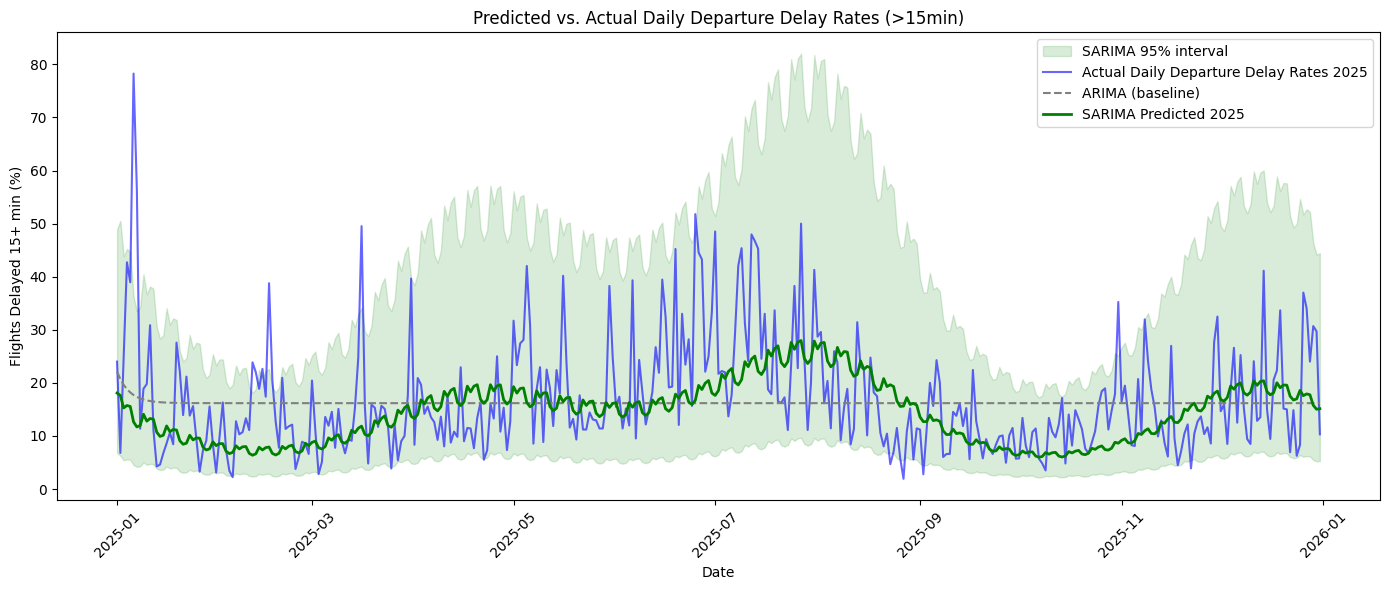

In [13]:
# Model 1: daily departure delay rate (% of flights delayed 15+ min)

# ARIMA + SARIMA on daily departure delay rate
predicted_rate_2025 = fit_and_forecast(daily_rate_24, lower=0, upper=100)
print(predicted_rate_2025.head())

# compares MAE and RMSE across ARIMA + SARIMA + 2024 average
score(predicted_rate_2025, daily_rate_25, "Departure Delay Rate")

# Visualization of results
plot_forecast(
    predicted_rate_2025,
    daily_rate_25,
    title="Predicted vs. Actual Daily Departure Delay Rates (>15min)",
    ylabel="Flights Delayed 15+ min (%)",
    actual_label="Actual Daily Departure Delay Rates 2025",
    filename="delay_rate_forecast"
)



In [23]:
# Save output:

score(predicted_rate_2025, daily_rate_25, "Departure Delay Rate").to_csv("delay_rate_accuracy.csv", index=False)
# Saves accuracy table as csv
fit_and_forecast(daily_rate_24, lower=0, upper=100).to_csv("delay_rate_results.csv", index=False)
# Saves ARIMA/SARIMA results and predictions


Departure Delay Rate: accuracy on 365 days of 2025
            Model  MAE  RMSE
     2024 Average 7.91 10.84
 ARIMA Prediction 7.88 10.77
SARIMA Prediction 7.24 10.39

Departure Delay Rate: accuracy on 365 days of 2025
            Model  MAE  RMSE
     2024 Average 7.91 10.84
 ARIMA Prediction 7.88 10.77
SARIMA Prediction 7.24 10.39
                                     SARIMAX Results                                     
Dep. Variable:              Departure Delay Rate   No. Observations:                  366
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood                -276.909
Date:                           Fri, 23 Oct 2026   AIC                            577.817
Time:                                   23:37:49   BIC                            624.649
Sample:                               01-01-2024   HQIC                           596.427
                                    - 12-31-2024                                         
Covariance Type:                  

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


                                     SARIMAX Results                                     
Dep. Variable:           Average Departure Delay   No. Observations:                  366
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood                -284.635
Date:                           Fri, 23 Oct 2026   AIC                            593.270
Time:                                   23:25:13   BIC                            640.101
Sample:                               01-01-2024   HQIC                           611.879
                                    - 12-31-2024                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0392      0.082      0.478      0.633      -0.122       0.200
sin1           0.0514      0.070      0.736

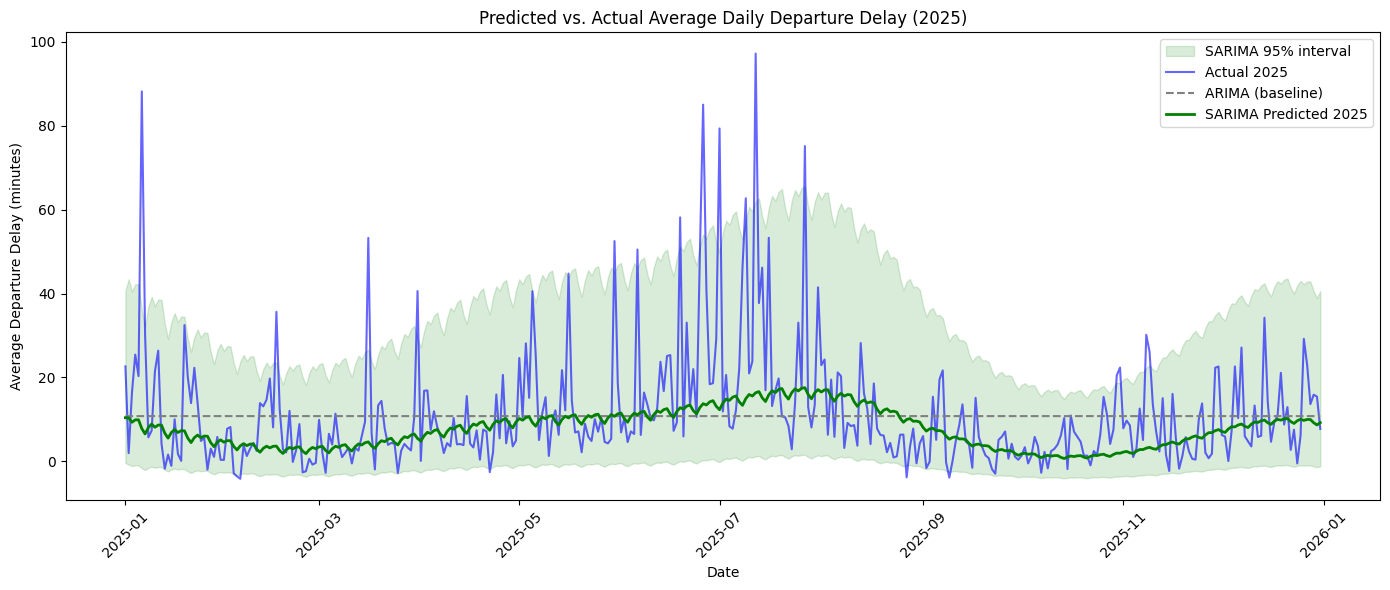

In [14]:
# Model 2: average daily departure delay (minutes)

# ARIMA + SARIMA on daily average dep delay
predicted_2025 = fit_and_forecast(daily_avg_24)
print(predicted_2025.head())

# compares MAE and RMSE across ARIMA + SARIMA + 2024 average
score(predicted_2025, daily_avg_25, "Average Departure Delay")

# Visualization of results
plot_forecast(
    predicted_2025,
    daily_avg_25,
    title="Predicted vs. Actual Average Daily Departure Delay (2025)",
    ylabel="Average Departure Delay (minutes)",
    actual_label="Actual 2025",
    filename="avg_delay_forecast"
)



In [22]:
# Save output:

score(predicted_2025, daily_avg_25, "Average Departure Delay").to_csv("avg_delay_accuracy.csv", index=False)
# Saves accuracies as csv
fit_and_forecast(daily_avg_24).to_csv("avg_delay_rate_results.csv", index=False)
# Saves ARIMA/SARIMA results and predictions


Average Departure Delay: accuracy on 365 days of 2025
            Model  MAE  RMSE
     2024 Average 9.27 14.21
 ARIMA Prediction 9.27 14.21
SARIMA Prediction 7.86 13.45

Average Departure Delay: accuracy on 365 days of 2025
            Model  MAE  RMSE
     2024 Average 9.27 14.21
 ARIMA Prediction 9.27 14.21
SARIMA Prediction 7.86 13.45
                                     SARIMAX Results                                     
Dep. Variable:           Average Departure Delay   No. Observations:                  366
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood                -284.635
Date:                           Fri, 23 Oct 2026   AIC                            593.270
Time:                                   23:35:37   BIC                            640.101
Sample:                               01-01-2024   HQIC                           611.879
                                    - 12-31-2024                                         
Covariance Type:            

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [24]:
# Monthly view: easier to judge whether the seasonal shape is right

monthly = pd.DataFrame({
    "Actual 2025": daily_avg_25.resample("MS").mean(),
    "SARIMA Predicted": predicted_2025.set_index("Date")["SARIMA Prediction"].resample("MS").mean(),
    "ARIMA Predicted": predicted_2025.set_index("Date")["ARIMA Prediction"].resample("MS").mean()
})

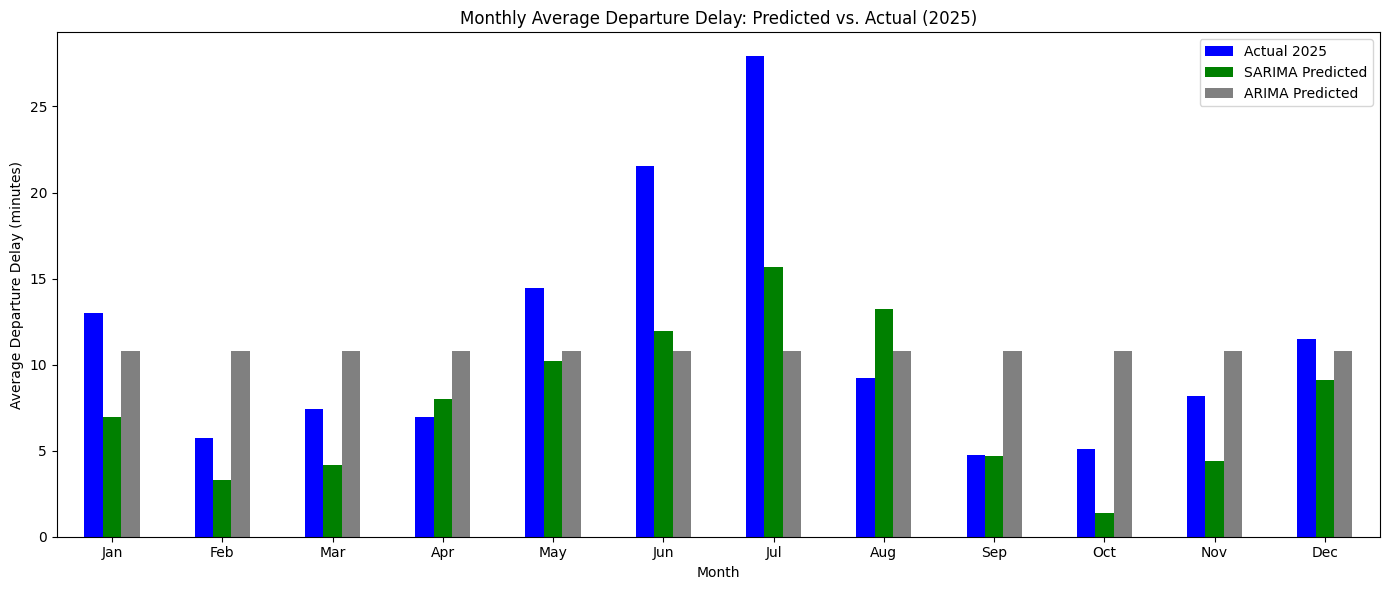

In [25]:
# Label rows by month name for the bar chart

# Monthly average departure delay: predicted vs actual (2025)
monthly.index = monthly.index.strftime("%b")

monthly.plot(kind="bar", figsize=(14, 6), color=["blue", "green", "gray"])
plt.title("Monthly Average Departure Delay: Predicted vs. Actual (2025)")
plt.xlabel("Month")
plt.ylabel("Average Departure Delay (minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("avg_delay_monthly.png", dpi=300, bbox_inches="tight")
plt.show()

# This bar chart provides a visualization of SARIMA/ARIMA predictions across months compared to actual monthly average flight delays.
# Both ARIMA and SARIMA do not predict larger spikes, especially in the summer months, and instead make more conservative predictons.
# SARIMA better captures yearly fluctuations, but predictions are consistently more conservative compared to the actual average delays.
